In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the unemployment dataset
df = pd.read_csv("Unemployment in India.csv")

# Display the first five records
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available in this folder:")
print(os.listdir())

Current working directory:
c:\OIBSIP\DataScience-Task2-UnemploymentAnalysis

Files available in this folder:
['README.md', 'Unemployment in India.csv', 'Unemployment_Analysis.ipynb']


In [4]:
import os
print(os.listdir())

['README.md', 'Unemployment in India.csv', 'Unemployment_Analysis.ipynb']


In [5]:
import pandas as pd
import glob

# Find CSV files in the project folder
csv_files = glob.glob("*.csv")

print("CSV files found:", csv_files)

# Load the dataset
if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nDataset loaded successfully!")
    display(df.head())
else:
    print("No CSV file found. Please check the filename and extension.")

CSV files found: ['Unemployment in India.csv']

Dataset loaded successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [6]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (768, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB

Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [7]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove missing values
df = df.dropna()

# Remove duplicate records
df = df.drop_duplicates()

# Reset row indexes
df = df.reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Updated dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset cleaned successfully!
Updated dataset shape: (740, 7)
Remaining missing values: 0
Remaining duplicate rows: 0


In [8]:
# Calculate average unemployment rate by state
state_unemployment = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by State:")
display(state_unemployment)

Average Unemployment Rate by State:


Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Punjab              12.031071
Puducherry          10.215000
Kerala              10.123929
Tamil Nadu           9.284286
Goa                  9.274167
Chhattisgarh         9.240357
West Bengal          8.124643
Telangana            7.737857
Maharashtra          7.557500
Andhra Pradesh       7.477143
Madhya Pradesh       7.406429
Sikkim               7.249412
Karnataka            6.676071
Gujarat              6.663929
Uttarakhand          6.582963
Assam                6.428077
Odisha               5.657857
Meghalaya            4.798889
Name: Estimated Unemployment Rate (%), dtype: float64

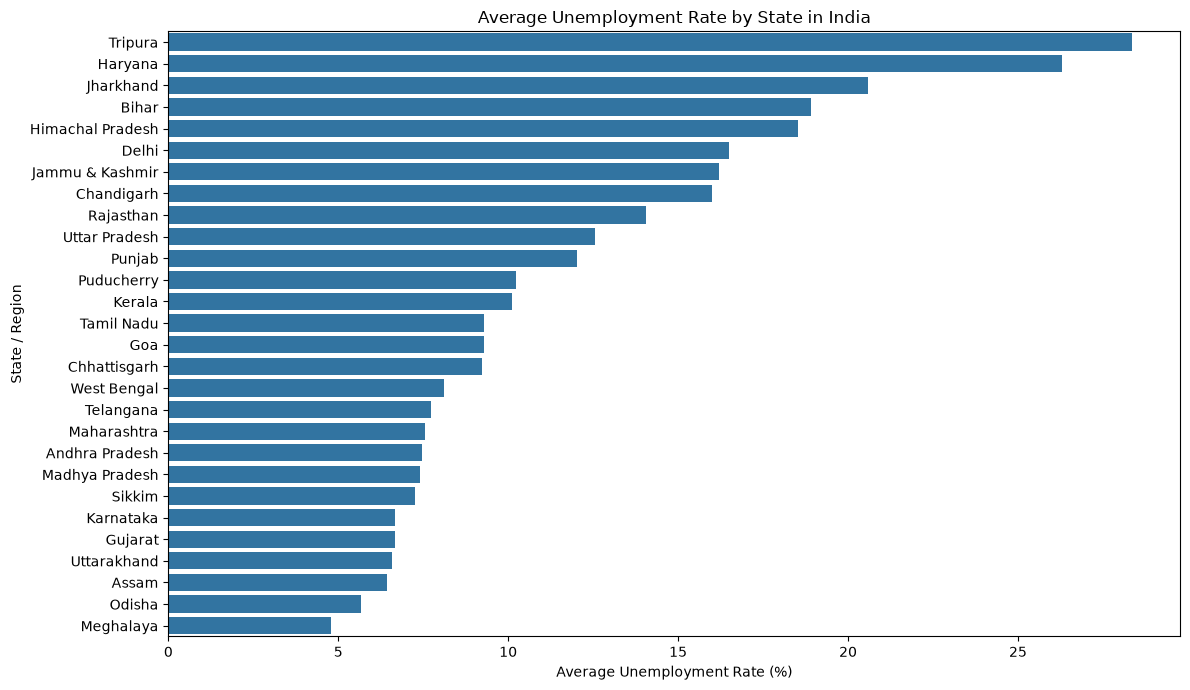

In [9]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_unemployment.values,
    y=state_unemployment.index
)

plt.title('Average Unemployment Rate by State in India')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('State / Region')
plt.tight_layout()
plt.show()

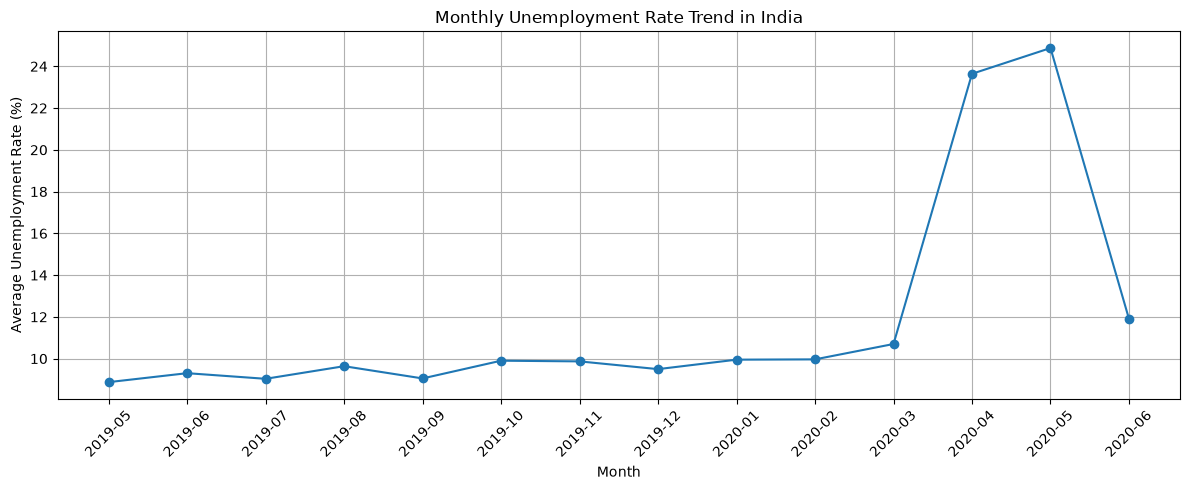

In [10]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Calculate average unemployment rate by month
monthly_unemployment = (
    df.groupby(df['Date'].dt.to_period('M'))[
        'Estimated Unemployment Rate (%)'
    ].mean()
)

# Plot monthly unemployment trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_unemployment.index.astype(str),
    monthly_unemployment.values,
    marker='o'
)

plt.title('Monthly Unemployment Rate Trend in India')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Average Unemployment Rate by Area:


Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64

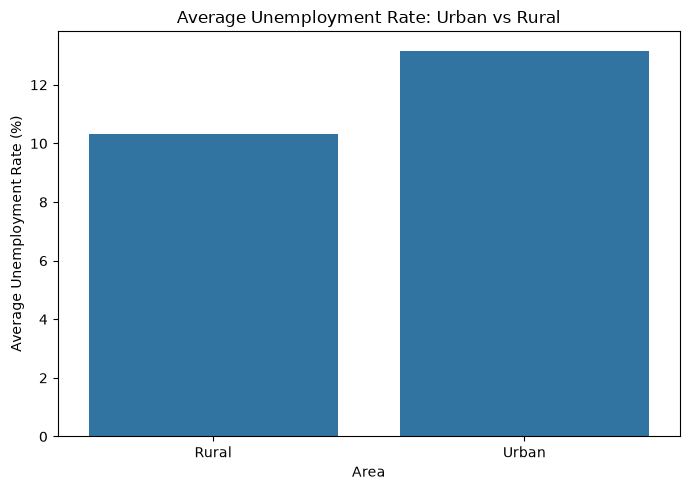

In [11]:
# Calculate average unemployment rate by area
area_unemployment = (
    df.groupby('Area')['Estimated Unemployment Rate (%)']
    .mean()
)

print("Average Unemployment Rate by Area:")
display(area_unemployment)

# Create a comparison chart
plt.figure(figsize=(7, 5))

sns.barplot(
    x=area_unemployment.index,
    y=area_unemployment.values
)

plt.title('Average Unemployment Rate: Urban vs Rural')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

Unemployment Before and After COVID-19 Lockdown:


Period
After Lockdown     17.774363
Before Lockdown     9.509534
Name: Estimated Unemployment Rate (%), dtype: float64

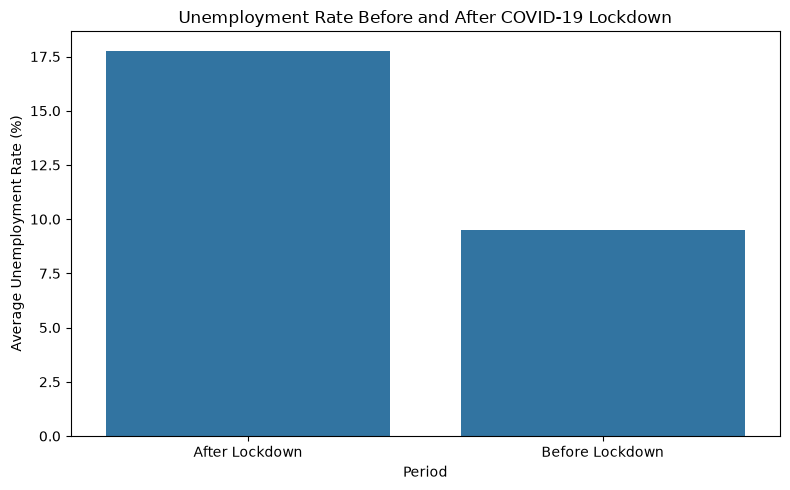

In [12]:
# Classify records into pre-lockdown and post-lockdown periods
df['Period'] = df['Date'].apply(
    lambda date: 'Before Lockdown'
    if date < pd.Timestamp('2020-03-25')
    else 'After Lockdown'
)

# Calculate average unemployment rate for both periods
covid_analysis = df.groupby('Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Unemployment Before and After COVID-19 Lockdown:")
display(covid_analysis)

# Visualise the comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    x=covid_analysis.index,
    y=covid_analysis.values
)

plt.title('Unemployment Rate Before and After COVID-19 Lockdown')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.tight_layout()
plt.show()

Average Labour Participation Rate by State:


Region
Tripura             61.823929
Meghalaya           57.080741
Telangana           53.002500
Gujarat             46.101071
Sikkim              46.070000
West Bengal         45.417500
Assam               44.868462
Himachal Pradesh    44.222143
Chhattisgarh        42.810714
Haryana             42.737143
Maharashtra         42.303214
Jharkhand           41.670714
Karnataka           41.345357
Punjab              41.138214
Jammu & Kashmir     41.030952
Tamil Nadu          40.872143
Rajasthan           39.973214
Uttar Pradesh       39.432500
Andhra Pradesh      39.375714
Chandigarh          39.336667
Goa                 39.249583
Puducherry          38.992692
Delhi               38.929643
Odisha              38.926429
Madhya Pradesh      38.821429
Bihar               38.153929
Kerala              34.867857
Uttarakhand         33.775556
Name: Estimated Labour Participation Rate (%), dtype: float64

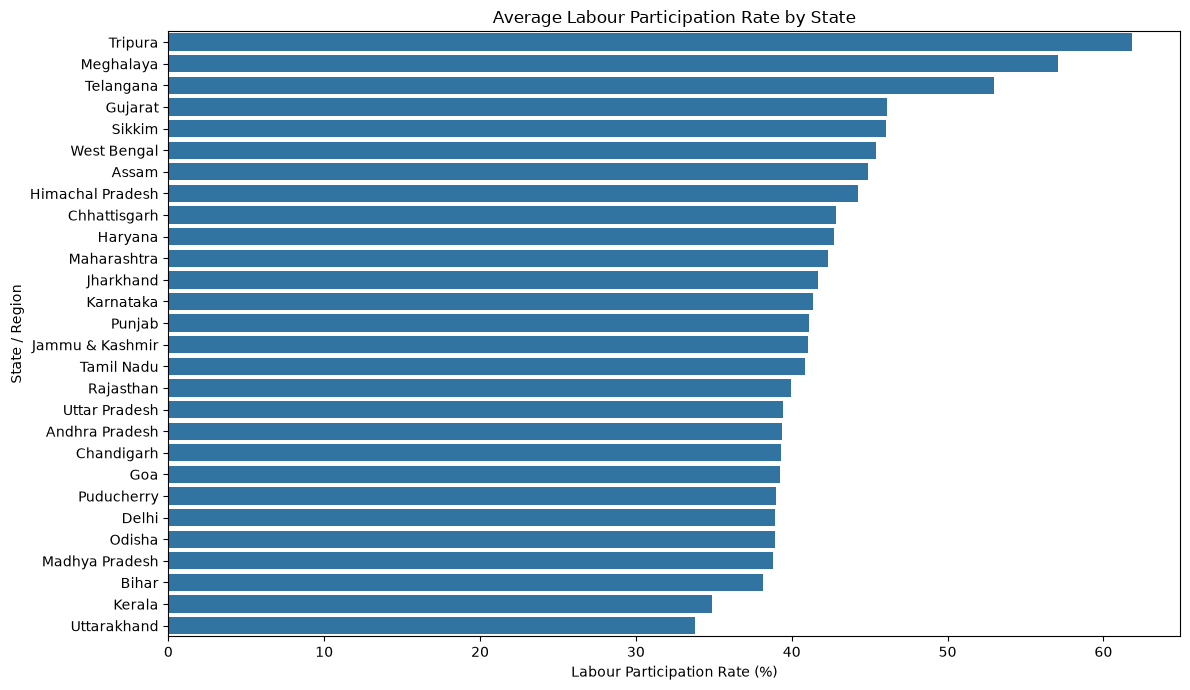

In [13]:
# Calculate average labour participation rate by state
state_lpr = (
    df.groupby('Region')['Estimated Labour Participation Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

print("Average Labour Participation Rate by State:")
display(state_lpr)

# Visualise the results
plt.figure(figsize=(12, 7))

sns.barplot(
    x=state_lpr.values,
    y=state_lpr.index
)

plt.title('Average Labour Participation Rate by State')
plt.xlabel('Labour Participation Rate (%)')
plt.ylabel('State / Region')
plt.tight_layout()
plt.show()

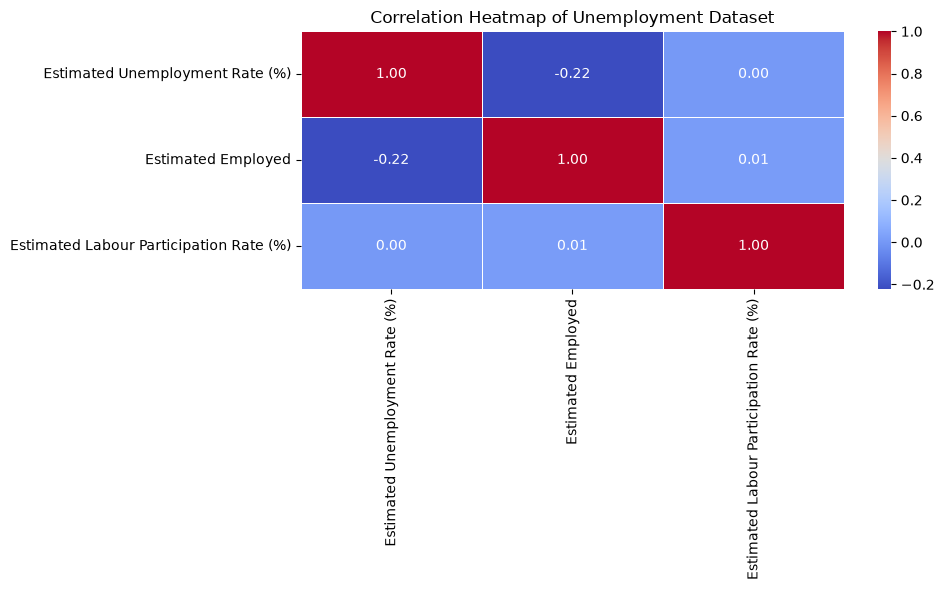

In [14]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Unemployment Dataset')
plt.tight_layout()
plt.show()

## Key Findings and Observations

1. **State-wise Analysis:** Unemployment rates vary across different states and regions of India.

2. **Time-based Trends:** Monthly analysis helps identify changes and fluctuations in unemployment rates over time.

3. **Urban vs Rural:** Comparing urban and rural areas helps identify differences in unemployment patterns.

4. **COVID-19 Impact:** The comparison before and after the lockdown highlights changes in unemployment during the pandemic period.

5. **Labour Participation:** Labour participation rates differ across states, reflecting variations in labour market activity.

6. **Correlation Analysis:** The correlation heatmap helps identify relationships between numerical variables in the dataset.

## Conclusion

This project explores unemployment trends in India using Python, Pandas, Matplotlib and Seaborn. Through data cleaning, statistical analysis and visualisation, it provides insights into state-wise unemployment, urban and rural differences, labour participation and changes during the COVID-19 period.

The analysis demonstrates how data science techniques can help understand real-world economic and employment patterns.